In [1]:
import xarray as xr

# load source data
da = xr.open_dataset('source_data/fig3_combo_slices_chess_20250924.h5')
da

<xarray.Dataset> Size: 4MB
Dimensions:                   (h: 283, k: 283)
Coordinates:
  * h                         (h) float64 2kB -70.5 -70.0 -69.5 ... 70.0 70.5
  * k                         (k) float64 2kB -70.5 -70.0 -69.5 ... 70.0 70.5
    sx                        (h, k) float64 641kB ...
    sy                        (h, k) float64 641kB ...
    sz                        (h, k) float64 641kB ...
    l                         float64 8B ...
Data variables:
    mac1_2                    (h, k) float32 320kB ...
    mac1_3                    (h, k) float32 320kB ...
    mac1_5                    (h, k) float32 320kB ...
    mac1_2 + mac1_3           (h, k) float32 320kB ...
    mac1_2 + mac1_5           (h, k) float32 320kB ...
    mac1_3 + mac1_5           (h, k) float32 320kB ...
    mac1_2 + mac1_3 + mac1_5  (h, k) float32 320kB ...

/var/folders/bs/hkvq730j1q7bscf60_pkcmq00000gn/T/ipykernel_89941/317957663.py:47: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


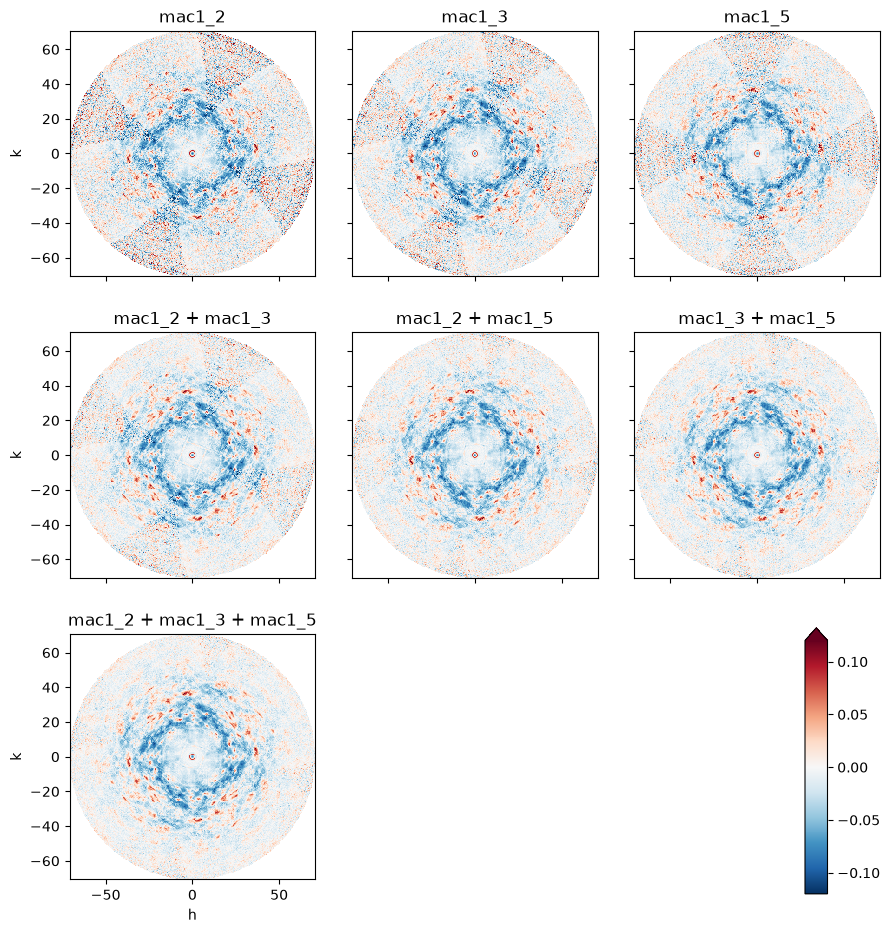

In [2]:
import matplotlib.pyplot as plt

plot_opts = dict(
    x="h", 
    y="k", 
    vmin=-0.12, 
    vmax=0.12, 
    cmap='RdBu_r', 
    add_colorbar=False, 
    rasterized=True,
)
fig, axes = plt.subplots(3, 3, figsize=(9, 9.5), sharex=True, sharey=True)

for j, name in enumerate(['mac1_2','mac1_3','mac1_5']):
    ax = axes[0,j]
    da[name].plot.pcolormesh(**plot_opts, ax=ax)
    ax.set_title(name)
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlabel('')
    if j > 0:
        ax.set_ylabel('')

for j, name in enumerate(['mac1_2 + mac1_3','mac1_2 + mac1_5','mac1_3 + mac1_5']):
    ax = axes[1,j]
    da[name].plot.pcolormesh(**plot_opts, ax=ax)
    ax.set_title(name)
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlabel('')
    if j > 0:
        ax.set_ylabel('')

# create a new axis to hold the colorbar
cbar_ax = fig.add_axes([0.9, 0.05, 0.025, 0.28]) 

for j, name in enumerate(['mac1_2 + mac1_3 + mac1_5','','']):
    ax = axes[2,j]
    if name:
        da[name].plot.pcolormesh(**(plot_opts | {'add_colorbar':True}), 
                                 cbar_kwargs={'label': ''}, 
                                 cbar_ax=cbar_ax,
                                 ax=ax)
        ax.set_title(name)
        ax.set_aspect('equal', adjustable='box')
    else:
        ax.set_axis_off()

plt.tight_layout()
fig.subplots_adjust(hspace=0.15, wspace=0.15) 

plt.savefig("export/fig3_slices.svg", transparent=True, bbox_inches="tight")
plt.savefig("export/fig3_slices.pdf", transparent=True, bbox_inches="tight")
plt.savefig("export/fig3_slices.png", transparent=True, dpi=300)